[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/paabL/rl-hvac-lab/blob/main/en/rl_lab_prototype_en.ipynb)

# Can one thermostat heat a thousand houses it has never seen?

**IFT3700/IFT6758 · Data Science · RL lab · prototype v2, English version**

In Lecture 2, RL was used to align LLMs with human preferences. Today we ask it for **general heating control**: one controller, the same weights for every house, with no model and no tuning for each one. We try it on 1,000 houses in Montreal in January, climbing a ladder with five rungs.

> ⚠️ **Run the Setup cell first.** It downloads the companion files (`lab_utils_en.py`, `schemas.py`, `agents/`, the weather CSV) by itself. If it cannot reach GitHub, it shows a button to upload **`rl_lab_en.zip`**. Skipping this cell gives `No module named 'lab_utils_en'`.

> **Prototype.** The solutions to the five exercises are already written in. The weather is **synthetic** for now. Agents are pre-trained on CPU (1,200 PPO iterations for the memory agents, about 20 minutes each, one random seed): the numbers come from this prototype, not from a final protocol.

<details><summary><b>Instructor notes: the lab in two minutes (click to open)</b></summary>

**The story.** A heat pump heats a house. Electricity costs 7× more at peak hours (weekday mornings and evenings). A good controller *preheats* before the peak, storing heat in the walls, and coasts through it. How much to preheat depends on the house (insulation, wall mass, heat-pump size), and the controller is **never told which house it is in**: it only sees temperatures, price and time.

**The question.** Can one learned policy do well in houses it has never seen? Each rung changes what the agent is trained on, and the agent must get smarter to keep up:

| Rung | Trained on | What the agent has to do |
| --- | --- | --- |
| Classic RL | one house | learn that house |
| Robust | random houses, no memory | find one compromise for all |
| Memorize or recognize | 4 or 16 houses, with memory | tell houses apart from their history |
| In context | a new house every episode | identify it within the episode |
| Meta-RL | the house changes mid-episode | keep re-identifying it |

**The key idea.** The house parameters are hidden but leave fingerprints: a leaky house cools fast, a small heat pump warms slowly. An agent with memory (a GRU) can in principle infer the house from how it responds, and adapt without any weight update. Section 5 shows why plain RL training struggles to discover this (the "saddle") and how an extra prediction task fixes it.

**What you need beforehand.** Standard ML (logistic regression, MLPs, overfitting, PyTorch basics). Every RL notion is introduced in the notebook. You do not need PPO in detail: it is "policy gradient with a safeguard against too-large updates".

**Live coding.** Each `EXERCISE k/5` cell has a `# YOUR CODE HERE` line followed by the solution. Delete the solution lines and write them live, or give students 3 to 5 minutes. Each exercise is followed by a test or a visible check.

**Suggested timing (2 h).** Setup 5 min · §1 why and the five regimes 10 · §2 problem 12 · §3 classic RL 20 · §4 robust 12 · §5 memory 25 · §6 memorize and in-context 13 · §7 meta-RL 18 · §8 wrap-up 5.

**What changed in v2.** A motivation section with the five regimes up front, three diagrams, more theory in short boxes (policy-gradient update, baseline, families of RL methods, PPO, actor-critic, self-predictive RL), and the half-life marked on the drift figure. The through-line is *general control*: each section ends with a box saying how far we got.

**Background, optional.** The lab is a small version of NOMAD, a research project on RL for building heating. You do not need it to teach.

</details>

## 0 · Setup

In [1]:
# Session settings
SHOW_WIDGETS = True    # interactive sliders (False: static figures instead)
RUN_TRAINING = False   # True: retrains the "classic" agent live (~2 min on CPU)
REAL_WEATHER = False   # True: replaces the synthetic weather with Montreal Januaries 2015-2024 from Open-Meteo (needs Internet)

# Companion files: lab_utils_en.py, schemas.py, agents/, montreal_weather.csv, all inside rl_lab_en.zip
import os, sys, urllib.request, zipfile
if not os.path.exists("lab_utils_en.py"):
    bundle = "rl_lab_en.zip"
    if not os.path.exists(bundle):
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/paabL/rl-hvac-lab/main/en/rl_lab_en.zip", bundle)
            print("Companion files downloaded from GitHub.")
        except OSError:                             # GitHub unreachable: ask for the zip
            try:
                from google.colab import files      # only exists in Colab
            except ImportError:
                raise FileNotFoundError("lab_utils_en.py not found: open this notebook from the unzipped rl_lab_en folder.")
            print("Download failed. Click 'Choose files' below and pick rl_lab_en.zip.")
            zips = [name for name in files.upload() if name.endswith(".zip")]
            assert zips, "That was not a .zip file: please upload rl_lab_en.zip."
            bundle = zips[0]
    zipfile.ZipFile(bundle).extractall(".")
sys.path.insert(0, ".")

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from lab_utils_en import *
from schemas import house_diagram, loop_diagram, agent_diagram
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
torch.set_num_threads(4)

if REAL_WEATHER:
    download_open_meteo().to_csv("montreal_weather.csv", index=False)
weather = load_weather()
print(f"{len(weather)} hours of January weather, from {weather.t_ext.min():.0f} to {weather.t_ext.max():.0f} °C")

14880 hours of January weather, from -29 to 11 °C


## 1 · Why control heating?

- **The stake.** Buildings in operation emitted 9.9 Gt of CO₂ in 2024, 26% of energy-related CO₂ (UNEP, *Global Status Report* 2026).
- **The lever.** Heating, ventilation and air conditioning (HVAC) are 38% of building energy (González-Torres et al., 2022).
- **The margin.** Reviews report 13 to 28% savings from better control (Drgoňa et al., 2020).
- **The peak.** In Quebec, on winter mornings and evenings, everyone heats at the same time. Hydro-Québec offers peak-time rates to spread demand: heat *before* the peak rather than during it.

Model predictive control (MPC) does this job very well... provided there is a model of each building. Building and calibrating that model house by house is too costly for millions of homes. Hence our through-line: **a general controller**. Can RL learn a single controller that adapts to each house on its own?

### The five regimes of the ladder

We never change the agent, only the world it trains in. At each rung it has to get a little smarter.

| Regime | In one sentence | Training world | Section |
| --- | --- | --- | --- |
| Classic RL | learn to control **one** given house | a single house | 3 |
| Robust | find **one compromise**, the same for every house | houses drawn at random, no memory | 4 |
| Memorize or recognize | recognize a house **already seen** in training | a few houses, with memory | 6 |
| Learn in context | estimate a house **never seen** by watching it, without changing its weights | a new house every episode | 6 |
| Meta-RL | **keep learning** when the house changes along the way | houses that change during the episode | 7 |

**Meta-RL in plain words: learning to learn.** During training the agent sees so many houses, and houses that change, that it learns a *way* of adapting. Once deployed, its weights no longer move: its memory learns the new house hour after hour, and relearns it if it changes.

<details><summary><b>Instructor notes: why and the regimes</b></summary>

Two minutes on the stake, then the key sentence: MPC is excellent but needs a model of each building, and that does not scale to millions of homes. Everything after is about a *general* controller. The regime table is the map of the lab: come back to it at the start of each section. The numbers come from the references cited; the lab claims no savings for real buildings.

</details>

## 2 · The problem: heating without paying peak prices

> **RL vocabulary** (new in this course)
> - **State** $s_t$: what the agent observes at hour $t$ (indoor and outdoor temperature, price, time of day).
> - **Action** $a_t$: the heat-pump power, from 0 to 100% in steps of 25%.
> - **Reward** $r_t = -\text{cost}_t$, with $\text{cost}_t = \text{price}_t \times \text{kWh}_t + \lambda \times \text{discomfort}_t$ (degree-hours outside 20-23 °C, $\lambda$ = 1 \$ per K·h).
> - **Return** $G_t = \sum_{k \ge t} r_k$: everything left to gain until the end of the week. The agent maximizes the return, not the next reward: paying a little now (preheating) can save more later.
> - **Policy** $\pi(a \mid s)$: the decision rule, the thing we learn.
> - **Episode**: one week, 168 hourly decisions, in one house.

**The house** has two temperatures: the air $T_a$, which reacts within minutes, and the thermal mass $T_m$ (walls, floors, furniture), which reacts over hours and is **invisible** to the thermostat. Each follows a heat balance, (heat capacity) × (rate of change) = sum of heat flows:

$$C_a \frac{dT_a}{dt} = \underbrace{UA\,(T_\text{ext} - T_a)}_{\text{loss to outside}} + \underbrace{H_{am}\,(T_m - T_a)}_{\text{exchange with the mass}} + Q_\text{pump} + \underbrace{Q_\text{int}}_{\text{people, appliances}}, \qquad C_m \frac{dT_m}{dt} = H_{am}\,(T_a - T_m)$$

Three parameters $\xi$ change from house to house, and the agent never sees them: the **insulation** $UA$ (W/K, heat lost per degree of difference with outside; higher means leakier), the **thermal mass** $C_m$ (J/K, how much heat the walls store) and the **heat-pump size** $\mu$ ($\mu = 1$: at full power the pump just holds 21 °C when it is -25 °C outside).

**The price** is peak on weekdays 6-9 am and 4-8 pm: 0.50 \$/kWh against 0.07 off-peak. The trick to learn: warm the walls *before* the peak, then coast through it. The thermal mass works like a battery.

**The heat pump** moves heat rather than making it: 1 kWh of electricity delivers COP kWh of heat (coefficient of performance), about 2.3 at -10 °C, less when it is colder.

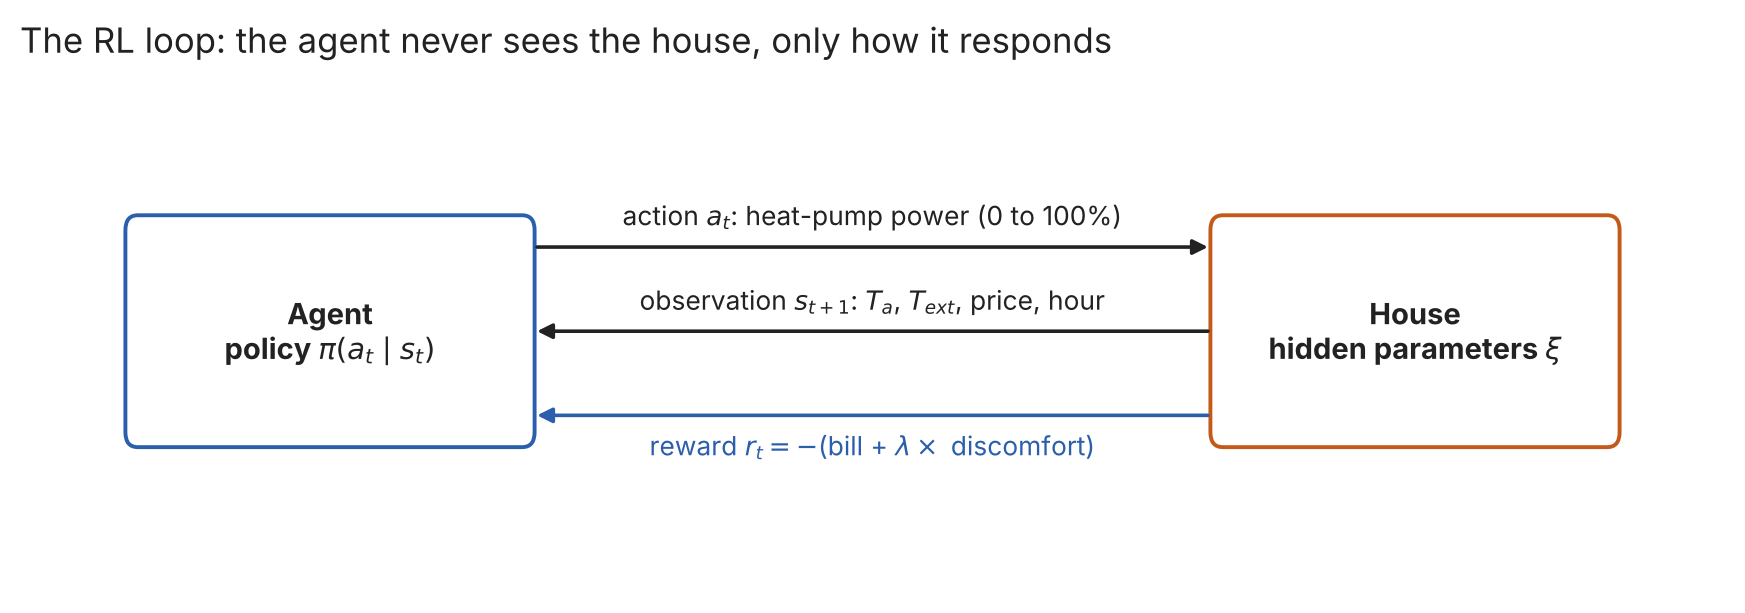

In [2]:
loop_diagram("en"); plt.show()

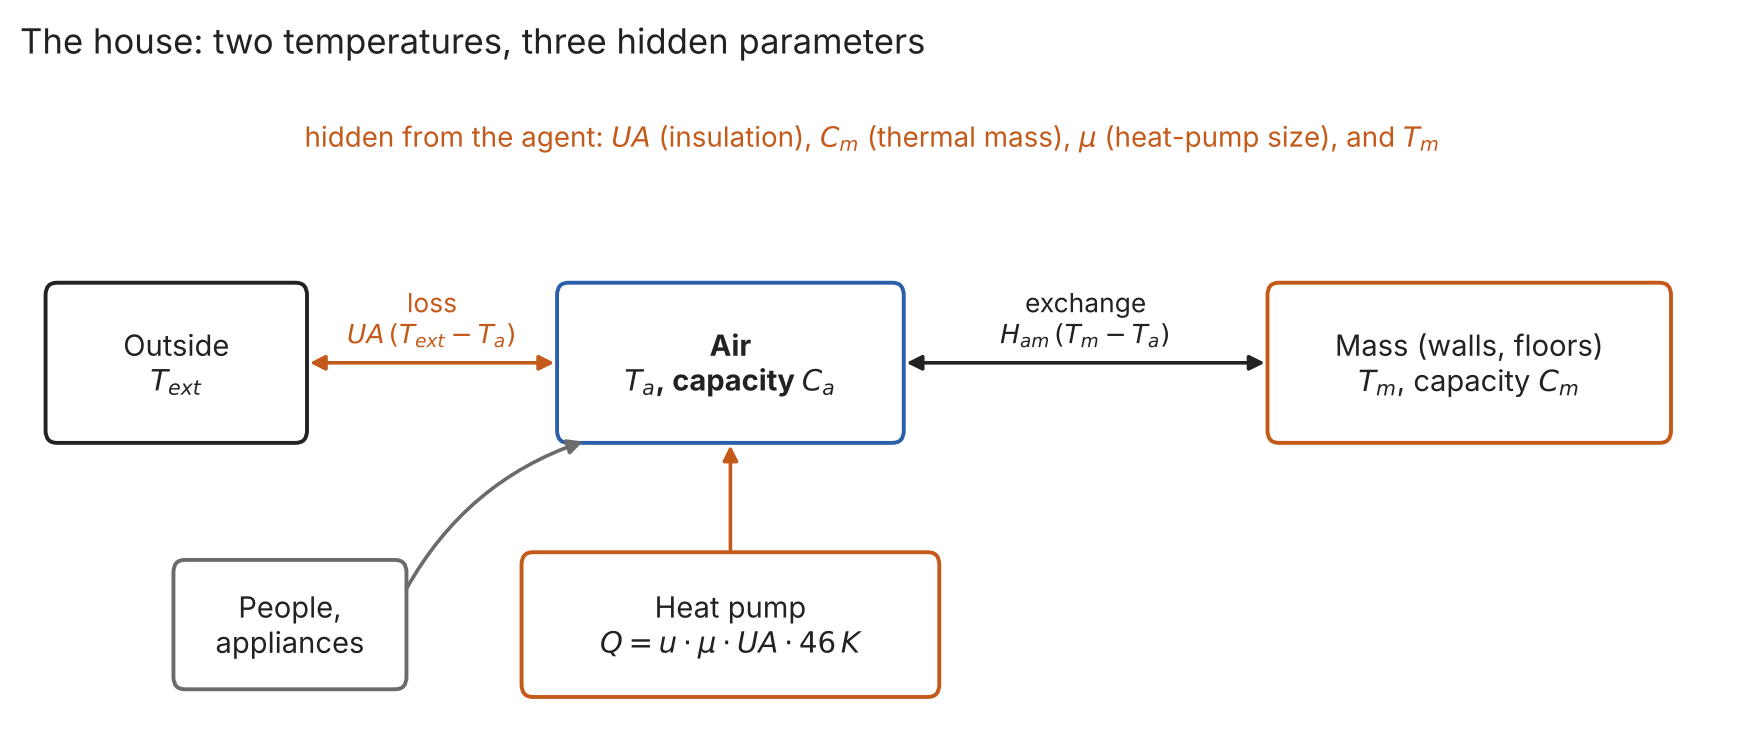

In [3]:
house_diagram("en"); plt.show()

In [4]:
# EXERCISE 1/5 · One hour of the two-temperature model (Euler method, 6 substeps of 10 min)
def my_thermal_step(Ta, Tm, u, t_ext, xi, substeps=6):
    q_pump = u * xi["mu"] * xi["UA"] * (T_SETPOINT - T_DESIGN)     # heat delivered (W)
    dt = 3600.0 / substeps                                          # seconds
    for _ in range(substeps):
        # YOUR CODE HERE: heat balance of the air (loss, exchange with the mass, pump, internal gains), then of the mass
        dTa = (xi["UA"] * (t_ext - Ta) + H_AM * (Tm - Ta) + q_pump + Q_INT) / C_AIR
        dTm = H_AM * (Ta - Tm) / xi["Cm"]
        Ta, Tm = Ta + dt * dTa, Tm + dt * dTm
    return Ta, Tm, q_pump / cop(t_ext) / 1000.0                     # electricity used (kWh) = heat / COP

xi_check = sample_houses(5, rng=np.random.default_rng(0))
print("Test:", np.allclose(my_thermal_step(20.0, 19.0, 0.5, -10.0, xi_check), thermal_step(20.0, 19.0, 0.5, -10.0, xi_check)))

Test: True


<details><summary><b>Instructor notes: exercise 1</b></summary>

The two equations above, written as code: rate of change = sum of heat flows ÷ heat capacity, then one Euler step `T += dt * dT`. Watts × seconds = joules, which is why `dt` is in seconds. The mass capacity Cm is about 4× the air capacity `C_AIR`, so the mass lags behind the air: this lag is what makes preheating possible, and what the thermostat cannot see.

</details>

Here are 64 random houses over one week, all heated by the same proportional thermostat set to 21 °C. Grey bands are peak hours.

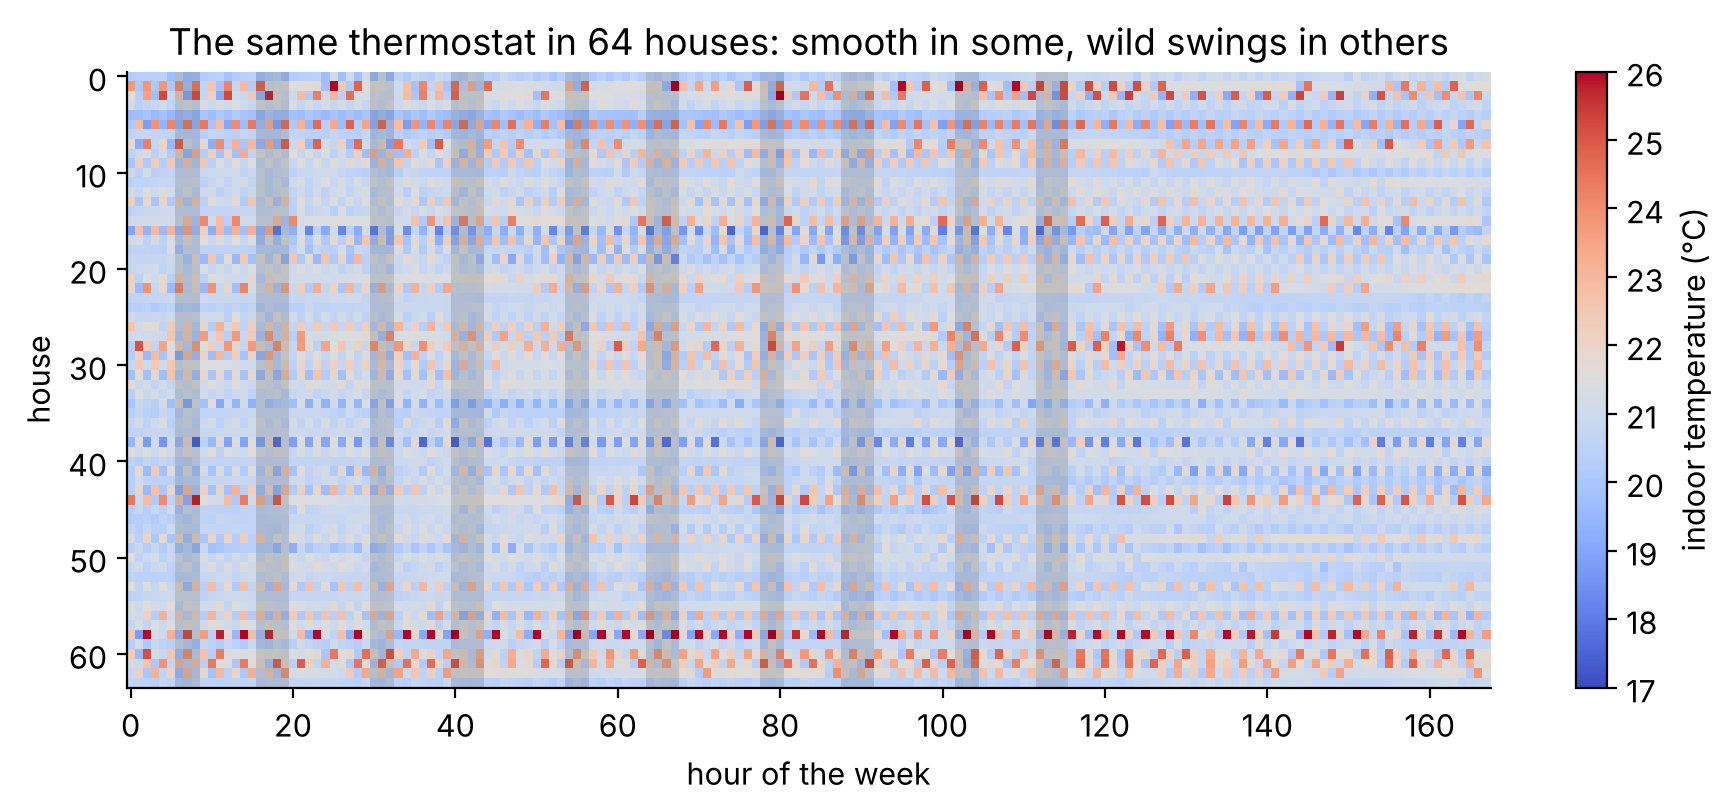

Mean cost: 10.36 $/day; from 1.63 to 50.30 depending on the house


In [5]:
xi_test, starts_test = test_bench(weather, n=256)      # 256 test houses and weather weeks, the same for every agent
d_th = evaluate(thermostat, weather, xi_test, starts_test)
peak = is_peak(np.arange(H))
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(d_th["Ta"][:64], aspect="auto", cmap="coolwarm", vmin=17, vmax=26)
for t in np.where(np.diff(np.r_[0, peak]) > 0)[0]:
    ax.axvspan(t - .5, t + 2.5 if t % 24 == 6 else t + 3.5, color="k", alpha=.12, lw=0)
ax.set(xlabel="hour of the week", ylabel="house", title="The same thermostat in 64 houses: smooth in some, wild swings in others")
plt.colorbar(im, label="indoor temperature (°C)"); plt.show()
print(f"Mean cost: {cost_per_day(d_th).mean():.2f} $/day; from {cost_per_day(d_th).min():.2f} to {cost_per_day(d_th).max():.2f} depending on the house")

<details><summary><b>Instructor notes: the thermostat in 64 houses</b></summary>

One row per house, one column per hour. Most rows stay close to 21 °C, but some houses swing hour after hour between too hot (red) and too cold (blue). Those are leaky houses with a big heat pump: one hour at high power overshoots, the next hour at low power undershoots. Well-insulated houses with a small pump stay smooth and cheap. Expected: about 10.4 \$/day on average, from about 1.6 to 50 \$/day depending on the house, mostly discomfort. The point: a rule tuned for the average house is wrong for many real ones.

</details>

## 3 · Classic RL: a single house

> **Reminder: Lecture 2.** Logistic regression is trained by $w_j \leftarrow w_j + \eta \sum_i (y_i - \hat y_i)\, x^i_j$.

> **The policy gradient.** We look for the weights $w$ that maximize the mean return $J(w) = \mathbb{E}_{\pi_w}[G_0]$. The policy-gradient theorem gives
> $$\nabla_w J = \mathbb{E}\Big[\sum_t G_t\, \nabla_w \log \pi_w(a_t \mid s_t)\Big].$$
> Our policy is a logistic regression on 7 features $x_t$: $\pi_w(\text{heat} \mid s_t) = \sigma(w^\top x_t)$. Then $\nabla_w \log \pi_w(a_t \mid s_t) = \big(a_t - \sigma(w^\top x_t)\big)\, x_t$, hence the **REINFORCE** update:
> $$w_j \leftarrow w_j + \eta \sum_t G_t\, \big(a_t - \sigma(w^\top x_t)\big)\, x_{t,j}.$$
> This is the logistic regression of Lecture 2: the label is the action taken, and each example is weighted by the return that followed it. Actions followed by a good return become more likely.

> **The baseline.** We replace $G_t$ by $G_t - b_t$, with $b_t$ the mean return at the same hour across houses. On average the gradient does not change (because $\mathbb{E}[\nabla \log \pi] = 0$), but it gets much less noisy.

bias         -0.57
Ta - 21      -2.13
T_ext / 10   -0.38
peak now     -0.44
peak soon    -0.06
sin hour      0.07
cos hour      0.02


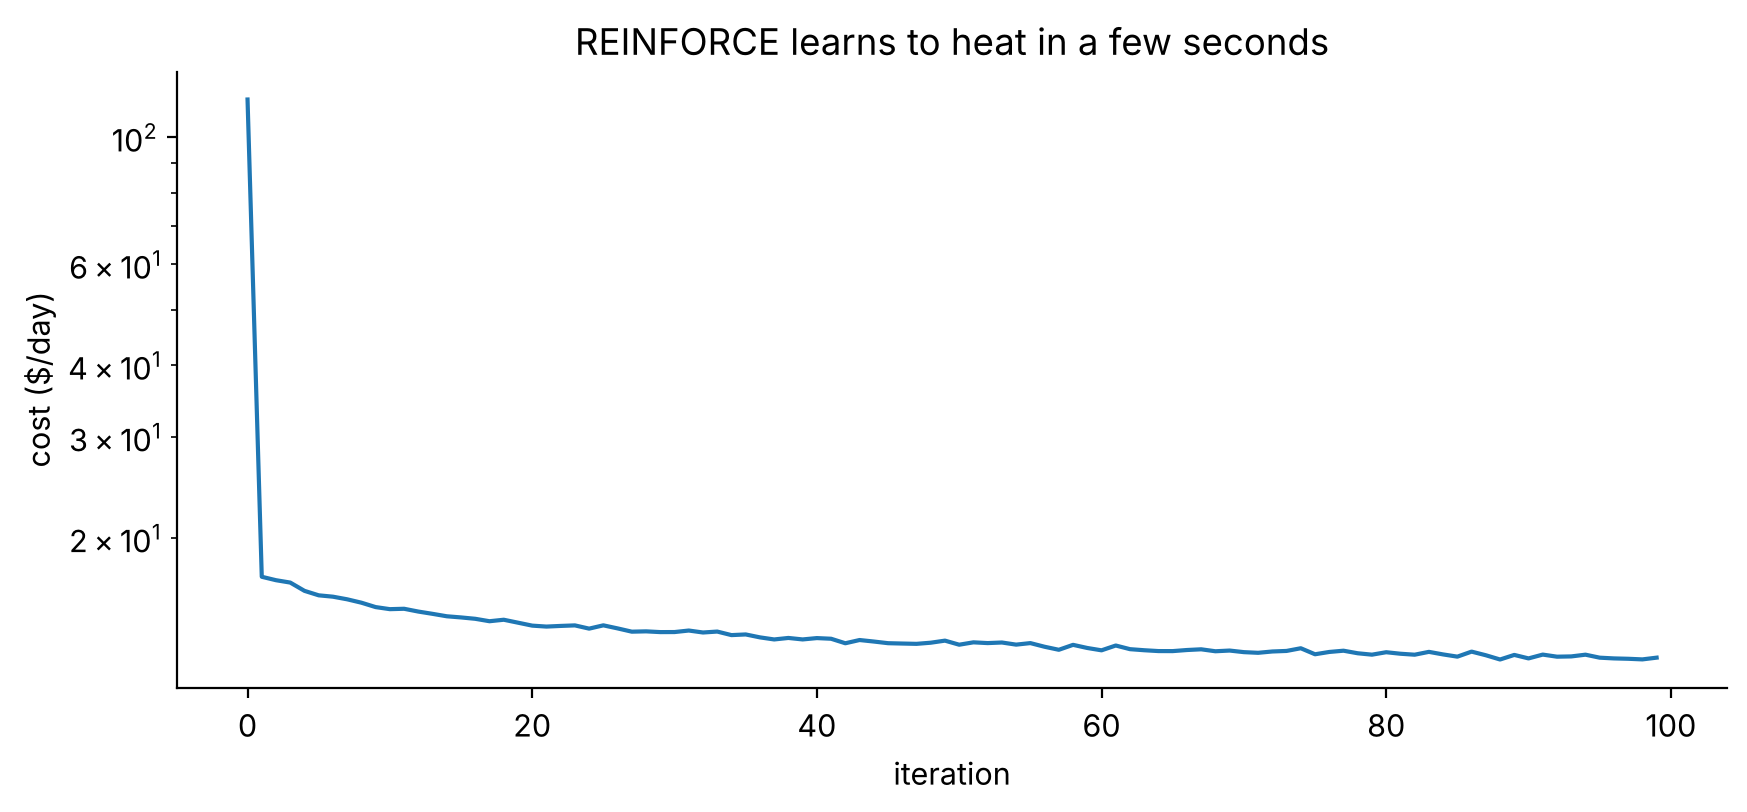

In [6]:
# EXERCISE 2/5 · The REINFORCE update
def my_update(w, X, A, P, G, eta):
    # X: (hours, houses, 7) features; A: actions taken, 0 or 1; P: probabilities π(heat); G: normalized returns
    # YOUR CODE HERE
    return w + eta * np.einsum("tn,tnj->j", G * (A - P), X) / (X.shape[0] * X.shape[1])

w, hist = reinforce(weather, iterations=100, eta=5.0, update=my_update, verbose=False)
names = ["bias", "Ta - 21", "T_ext / 10", "peak now", "peak soon", "sin hour", "cos hour"]
print(pd.Series(w, index=names).round(2).to_string())
plt.plot(hist); plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("cost ($/day)"); plt.title("REINFORCE learns to heat in a few seconds"); plt.show()

<details><summary><b>Instructor notes: exercise 2</b></summary>

The `einsum` is the sum over hours t and houses n of G · (a − p) · x_j, divided by the number of examples. Without G, it is exactly the logistic-regression gradient with the actions as labels. G has been normalized, and the mean over houses at the same hour has been subtracted (a *baseline*): this does not change the direction of the gradient on average, it only reduces its noise. Expected: the cost drops from about 116 \$/day (all weights at 0: a coin flip every hour) to about 12 \$/day in a few seconds. That is still worse than the plain thermostat of the next cell: heating at full power or not at all is too coarse.

</details>

**Question:** read the weights as you would for a logistic regression. Why is the weight of "Ta - 21" strongly negative? And the weight of "peak now"? Why does "peak soon" stay close to 0?

<details><summary><b>Answer</b></summary>

- **Ta - 21** (about -2.1): the warmer the house, the less it heats. The agent has rediscovered the thermostat on its own.
- **peak now** (about -0.4): electricity costs 7× more, so it heats less during the peak.
- **T_ext / 10** (about -0.4): colder outside (negative T_ext) means more heating.
- **peak soon** (about -0.06, close to 0): this linear on/off agent did *not* learn to preheat. That takes a richer agent: next cell.

</details>

### Policy gradient is only one family among several

| Family | What is learned | Examples | In this lab |
| --- | --- | --- | --- |
| Policy gradient | the policy $\pi$ directly | REINFORCE, PPO | REINFORCE here; PPO for every later agent |
| Actor-critic | $\pi$ and a value $V$ used as a baseline | A2C, PPO, SAC | our agents: an actor head and a critic head |
| Value-based | the value $Q(s, a)$ of each action, then take the best | Q-learning, DQN | — |
| Model-based | a model of the dynamics, then plan | MPC, Dyna, MuZero | MPC, played here by the oracle |
| Imitation | copy an expert | behavior cloning, DAgger | — |

> **PPO in one sentence.** A policy gradient with a critic and a safeguard: it reuses each batch of experience several times, but clips the update as soon as the new policy drifts too far from the old one (the ratio $\pi_{new}/\pi_{old}$ is kept within $[0.8, 1.2]$). That is what makes training stable.

An on/off agent is crude. The same principle with five power levels, a memory and the PPO algorithm gives the "classic" agent. PPO is a policy-gradient method like REINFORCE, with a safeguard that keeps each update small, which makes training stable. Trained on this single house, it learns to preheat before the peak.

thermostat                     7.70 $/day
preheating thermostat          6.55 $/day


classic agent                  6.02 $/day


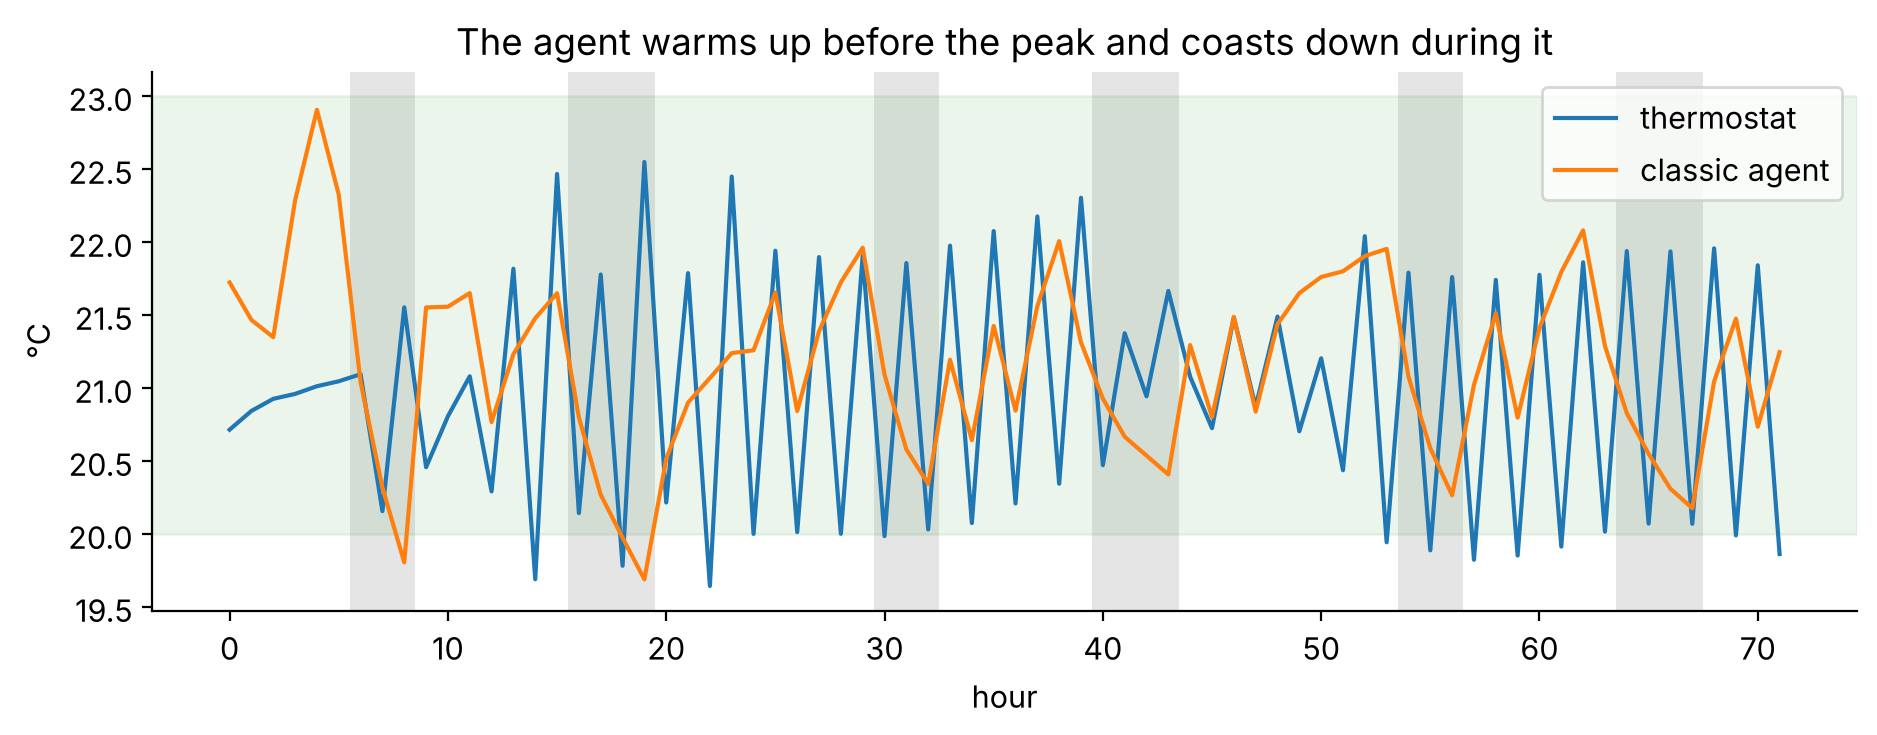

In [7]:
if RUN_TRAINING:
    classic_agent = Agent(memory=True)
    train(classic_agent, Houses(weather, 256, xi=lambda: nominal_house(256), seed=1), iterations=80)
else:
    classic_agent, _ = load_agent("classic")

xi_nom = nominal_house(256)
for name, pol in [("thermostat", thermostat), ("preheating thermostat", preheating_thermostat), ("classic agent", classic_agent)]:
    print(f"{name:28s} {cost_per_day(evaluate(pol, weather, xi_nom, starts_test)).mean():6.2f} $/day")

fig, ax = plt.subplots(figsize=(11, 3.5))
for name, pol in [("thermostat", thermostat), ("classic agent", classic_agent)]:
    ax.plot(evaluate(pol, weather, xi_nom, starts_test)["Ta"][0, :72], label=name)
for t in np.where(is_peak(np.arange(72)) > 0)[0]:
    ax.axvspan(t - .5, t + .5, color="k", alpha=.1, lw=0)
ax.axhspan(*COMFORT_BAND, color="g", alpha=.08); ax.set(xlabel="hour", ylabel="°C", title="The agent warms up before the peak and coasts down during it"); ax.legend(); plt.show()

<details><summary><b>Instructor notes: the classic agent</b></summary>

Expected on the average ("nominal") house: thermostat about 7.7, hand-written preheating thermostat about 6.6, classic agent about 6.0 \$/day. The agent beats the hand-written rule because it learned *how much* and *when* to preheat for this particular house. On the plot, grey = peak hours, green = comfort band (20-23 °C). The thermostat zigzags because it only reacts to the current temperature with 5 power levels; the agent rises before each peak and drifts down during it. This is classic RL: trained and tested on the same environment.

</details>

> **On a known house, RL is useless: MPC is enough.** If the model of the house is known (its parameters $\xi$), model predictive control directly optimizes the next hours from the weather and price forecasts, with no training at all. In our numbers, the **oracle**, an agent that is given $\xi$, plays that role. RL becomes interesting when we want **one controller for every house**, with no model of each.

> **Towards general control.** The classic agent knows a single house: it is not general at all. Let us see what it does elsewhere.

## 4 · Robust: one compromise for all houses

The classic agent knows a single house. To drive a thousand, we train on houses drawn at random: this is the **data augmentation** of Lectures 1 and 7, called *domain randomization* in RL. A memoryless agent (an MLP that only sees the current observation) cannot tell houses apart, so the best it can learn is one compromise that works reasonably everywhere.

In [8]:
# EXERCISE 3/5 · Draw n houses: ξ = nominal × exp(U(-w, w)), w = width × log(sqrt(factor))
def my_houses(n, width=1.0, rng=np.random.default_rng(0)):
    # YOUR CODE HERE
    return {k: NOMINAL[k] * np.exp(rng.uniform(-1, 1, n) * width * np.log(np.sqrt(FACTOR[k]))) for k in NOMINAL}

xi_demo = my_houses(2000)
print({k: (round(v.min(), 2), round(v.max(), 2)) for k, v in xi_demo.items()})

{'UA': (np.float64(86.62), np.float64(259.67)), 'Cm': (np.float64(17325236.71), np.float64(51936750.29)), 'mu': (np.float64(0.92), np.float64(2.77))}


<details><summary><b>Instructor notes: exercise 3</b></summary>

Drawing uniformly in log space makes "twice as leaky" and "half as leaky" equally likely. With a factor of 3, each parameter ranges from nominal ÷ √3 to nominal × √3: for instance UA from about 87 to 260 W/K. This "box" of houses is the training world of every agent from here on.

</details>

thermostat                  10.36 $/day   gap to oracle  +87.5 %
classic (one house)         12.50 $/day   gap to oracle +126.3 %
robust (no memory)           6.09 $/day   gap to oracle  +10.4 %
oracle (sees ξ)              5.52 $/day   gap to oracle   +0.0 %


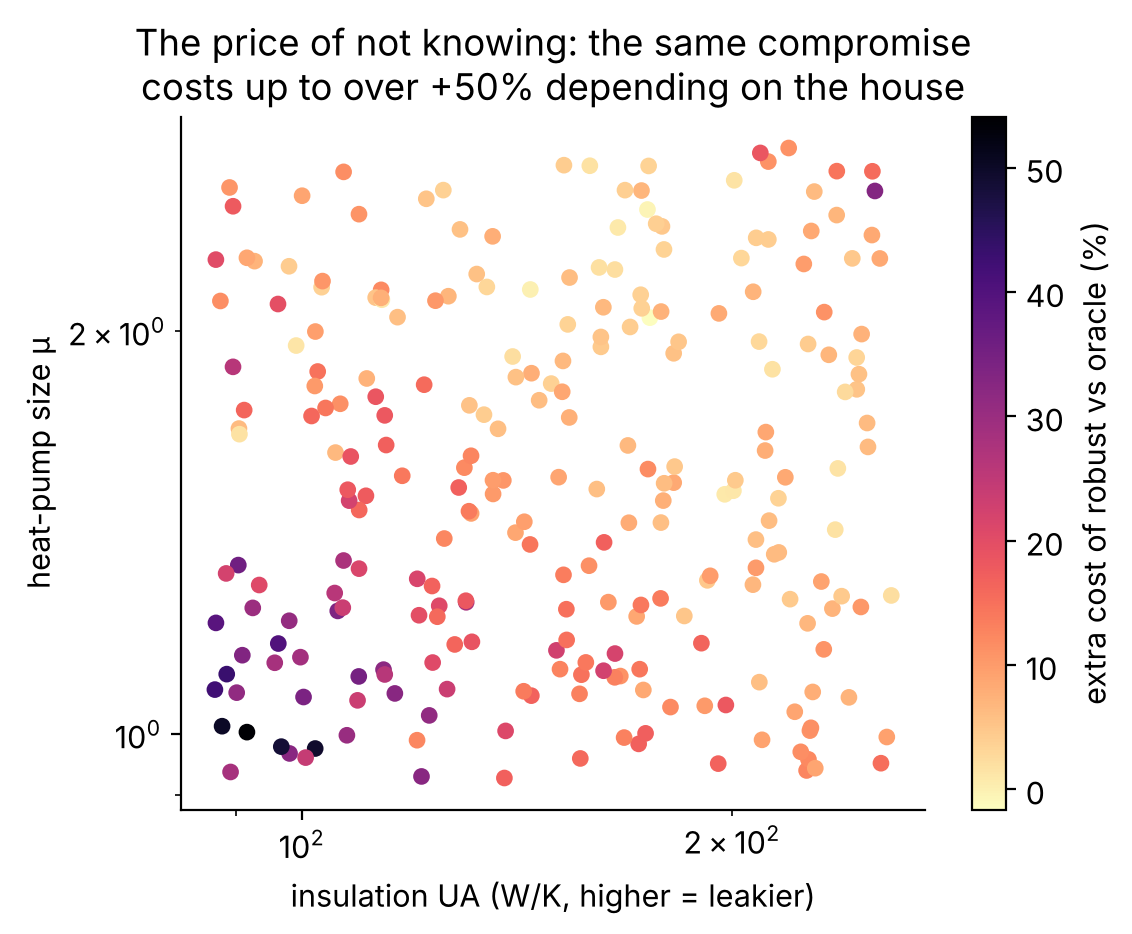

In [9]:
oracle, _ = load_agent("oracle")      # is told ξ and the mass temperature: the yardstick, not a real controller
robust, _ = load_agent("robust")      # no memory, trained on random houses
res = {}
res["thermostat"] = cost_per_day(d_th)
res["classic (one house)"] = cost_per_day(evaluate(classic_agent, weather, xi_test, starts_test))
res["robust (no memory)"] = cost_per_day(evaluate(robust, weather, xi_test, starts_test))
res["oracle (sees ξ)"] = cost_per_day(evaluate(oracle, weather, xi_test, starts_test, privileged=True))
for k, v in res.items():
    print(f"{k:26s} {v.mean():6.2f} $/day   gap to oracle {100 * (v.mean() / res['oracle (sees ξ)'].mean() - 1):+6.1f} %")

gap = 100 * (res["robust (no memory)"] / res["oracle (sees ξ)"] - 1)
plt.figure(figsize=(6, 4.5))
sc = plt.scatter(xi_test["UA"], xi_test["mu"], c=gap, cmap="magma_r", s=25)
plt.colorbar(sc, label="extra cost of robust vs oracle (%)")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("insulation UA (W/K, higher = leakier)"); plt.ylabel("heat-pump size μ")
plt.title("The price of not knowing: the same compromise\ncosts up to over +50% depending on the house"); plt.show()

<details><summary><b>Instructor notes: robust vs oracle</b></summary>

The **oracle** is the same kind of network, but it is *told* ξ and the hidden mass temperature. No real controller has that, so it serves as a yardstick: the gap to the oracle is the price of not knowing the house. Expected gaps: thermostat about +88%, classic agent about +126% (worse than the thermostat: it is tuned for a house it is not in), robust about +10%. The scatter shows where the compromise hurts: the worst cases sit in the bottom-left corner, well-insulated houses with a small heat pump, cheap to heat, where the compromise wastes almost 1 \$/day out of about 2.6. That last gap is what a memory could, in principle, win back.

</details>

> **Towards general control.** One controller for every house: done, at about +10% above the oracle. But it is blind to the house. To do better, it would have to recognize it.

## 5 · Does the agent listen to its memory?

> **Why a memory can recognize the house.** Heating, then watching how the temperature responds, is what engineers do to model a building: **system identification**. A leaky house cools fast when the heat is cut; a small heat pump warms slowly when pushed. With a few hours of history (power requested, temperatures), a simple regression would estimate $UA$, $C_m$ and $\mu$. A memory can do this computation implicitly, without being told what to look for... if training pushes it to.

So we give the agent a memory: a GRU, which you can read as an MLP that reads its own previous output, $h_t = f(W[x_t, h_{t-1}] + w_0)$. On top of it, three heads.

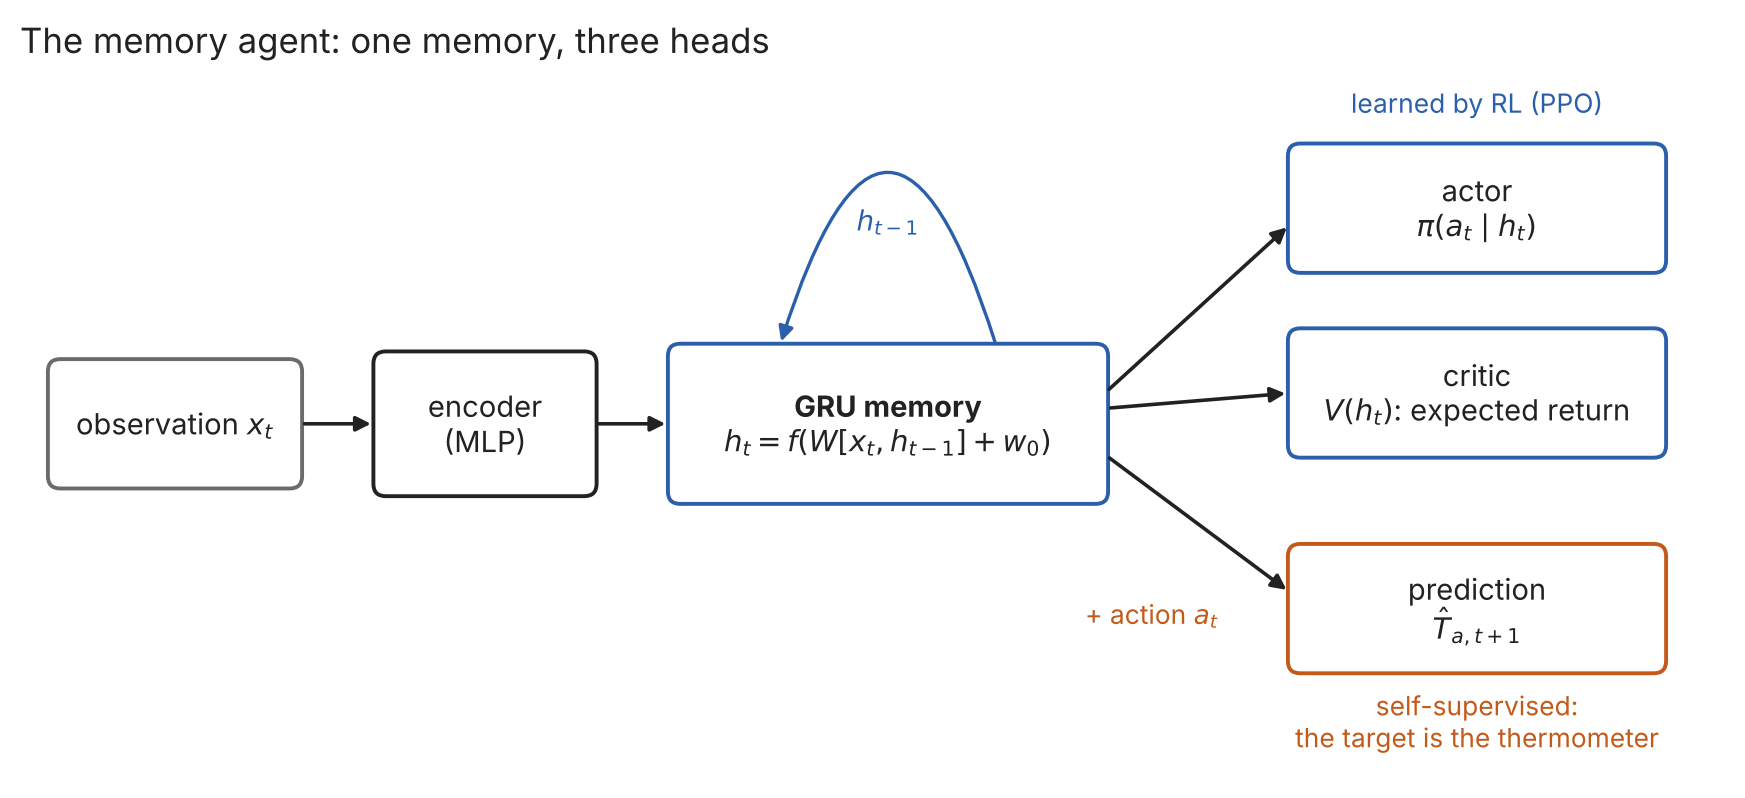

In [10]:
agent_diagram("en"); plt.show()

> **Actor-critic.** The actor picks the action. The critic $V(h_t)$ predicts the expected return and serves as a baseline: the actor learns from the **advantage** $A_t = G_t - V(h_t)$, "better or worse than expected". It is the baseline of Section 3, but learned.

> **Self-predictive RL.** The reward says whether the action was good, not what the house is: a weak, noisy signal for learning to identify it. The third head adds a self-supervised task: predict next hour's temperature from the memory and the action. The target is free, it is the thermometer. To predict well, the memory must contain the house. Making the agent predict its own future (*self-predictive RL*) helps a lot when the state is hidden (Schwarzer et al., 2021; Ni et al., 2024).

A toy with two weights shows why RL alone struggles. The memory writes $m = c\,\xi + \varepsilon$ (what it stores about the house, plus noise), the action reads $a = b\,m$, and the ideal action is $\xi$:

$$J(b, c) = \sigma_\xi^2\,(bc - 1)^2 + b^2 \sigma_\varepsilon^2$$

Here $\sigma_\xi$ measures how different the houses are and $\sigma_\varepsilon$ the noise. At $(0, 0)$, the robust policy, reading brings nothing while the memory is empty, and writing brings nothing while nobody reads: the gradient is zero. $(0, 0)$ is a **saddle point**, and gradient descent can linger there.

In [11]:
# EXERCISE 4/5 · The gradient of the toy
def my_grad_J(b, c, s_xi=1.0, s_eps=1.0):
    # YOUR CODE HERE: dJ/db, dJ/dc
    return 2 * s_xi**2 * (b * c - 1) * c + 2 * b * s_eps**2, 2 * s_xi**2 * (b * c - 1) * b

print("Gradient at the saddle (0, 0):", my_grad_J(0.0, 0.0), "   Test:", np.allclose(my_grad_J(.3, -.7), grad_J(.3, -.7)))

def landscape(s_xi=1.0, head=0.0):
    bs = np.linspace(-1.5, 1.5, 200); B, Cc = np.meshgrid(bs, bs)
    plt.figure(figsize=(5.5, 5)); plt.contourf(B, Cc, np.log(J(B, Cc, s_xi) + head * (1 - Cc) ** 2 + 1e-3), 30, cmap="Blues_r")
    rng = np.random.default_rng(1)
    for _ in range(20):
        b, c = rng.normal(0, 1e-3, 2)        # start very close to the saddle
        traj = [(b, c)]
        for _ in range(150):
            gb, gc = my_grad_J(b, c, s_xi)
            gc += -2 * head * (1 - c)        # the prediction head: a gradient for writing that does not go through reading
            b, c = b - 0.03 * gb, c - 0.03 * gc
            traj.append((b, c))
        traj = np.array(traj); plt.plot(traj[:, 0], traj[:, 1], "w-", lw=1); plt.plot(*traj[-1], "wo", ms=4)
    plt.plot(0, 0, "r*", ms=14, label="saddle: robust policy"); plt.xlim(-1.5, 1.5); plt.ylim(-1.5, 1.5)
    plt.xlabel("b: read the memory"); plt.ylabel("c: write the house into memory")
    plt.title(f"σξ = {s_xi:.1f}, prediction head = {head:.1f}"); plt.legend(loc="lower left"); plt.show()

if SHOW_WIDGETS:
    import ipywidgets as W
    W.interact(landscape, s_xi=W.FloatSlider(1.0, min=0.3, max=2.0, step=0.1, description="spread σξ"),
               head=W.FloatSlider(0.0, min=0.0, max=1.0, step=0.1, description="head"))
else:
    landscape(1.0, 0.0); landscape(2.0, 0.0); landscape(1.0, 0.5)

Gradient at the saddle (0, 0): (0.0, -0.0)    Test: True


interactive(children=(FloatSlider(value=1.0, description='spread σξ', max=2.0, min=0.3), FloatSlider(value=0.0…

<details><summary><b>Instructor notes: exercise 4 and how to read the plot</b></summary>

Differentiate J by hand (chain rule). At (0, 0) both partial derivatives are 0: nothing pushes the agent to start using its memory.

Reading the plot: dark blue = low cost. The valley is the curve bc = 1 (read × write = 1: the memory stores the house and the action uses it). The white lines are 20 runs of gradient descent started right next to the red star; the white dots are where they are after 150 steps. The **head** slider adds a term (1 − c)² that rewards writing the house into memory for its own sake: this is what the prediction head does in the real agent (next cells).

</details>

**Question:** widening the box of houses ($\sigma_\xi$) deepens the valley. Does it make the runs leave the saddle faster? What changes when the prediction head is switched on?

<details><summary><b>Answer</b></summary>

Yes, a wider box makes the runs leave faster: the escape direction gets steeper (its curvature grows like σξ²). With σξ = 2 every run reaches a valley; with σξ = 1 they have barely left the star after 150 steps; with σξ = 0.3 they do not move at all. But the gradient at exactly (0, 0) is still zero, so escaping still relies on the tiny random start.

The head gives c a gradient of its own: the memory starts storing the house right away, because that helps predict the temperature. Once the memory holds something, reading it pays off and b follows. Every run reaches the valley, even at σξ = 1.

(The two valleys, top right and bottom left, are equivalent: storing −ξ and reading it with a minus sign works just as well.)

</details>

Same experiment on the real agents: a GRU trained by PPO **without** a prediction head, and the same GRU **with** the head.

In [12]:
saddle, _ = load_agent("saddle")
in_context, _ = load_agent("in_context")
rows = []
for name, ag in [("GRU, no head (saddle)", saddle), ("GRU + head", in_context)]:
    d = evaluate(ag, weather, xi_test, starts_test)
    res[name] = cost_per_day(d)
    rows.append(dict(agent=name, cost=res[name].mean(),
                     erase_memory=erase_effect(ag, weather, xi_test, starts_test),
                     swap_memory=swap_effect(ag, weather, xi_test, starts_test),
                     **{f"probe R2 h{t}": r for t, r in probe(d, (6, 24, 72, 167)).items()}))
tab = pd.DataFrame(rows).set_index("agent").round(2)
tab

,cost,erase_memory,swap_memory,probe R2 h6,probe R2 h24,probe R2 h72,probe R2 h167
agent,,,,,,,
"GRU, no head (saddle)",5.85,14.10,10.57,0.39,0.62,0.61,0.62
GRU + head,5.69,5.44,23.16,0.43,0.63,0.61,0.64


Each column is an experiment on the agent's memory:
- **cost**: \$/day on the 256 test houses.
- **erase_memory**: wipe the memory at hour 72; extra cost over the next 24 hours (%).
- **swap_memory**: swap the memories of two houses at hour 72, so each agent "believes" it is in the other house; extra cost over the next 24 hours (%).
- **probe R2**: a scikit-learn Ridge regression reads $\xi$ from the memory at hours 6, 24, 72 and 167; $R^2$ on houses the probe never saw. It measures what the memory *knows*, not whether the policy *uses* it.

**Question:** which agent really *listens to* its memory? Which one knows something without using it?

<details><summary><b>Answer</b></summary>

Both memories *know* the house about equally well: from hour 24 on, the probes give R² ≈ 0.6 for both. The difference is in how the policy *uses* it.

- **GRU + head**: swapping memories costs **+23%**, much more than wiping them (+5%). The agent acts on what its memory says about the house, so being handed another house's memory hurts. It reads its memory.
- **GRU without head**: a swap costs **+11%**, *less* than a wipe (+14%). Its memory mostly carries generic short-term information (recent temperatures, time of day) that another house's memory provides just as well; the house-specific part is barely used. It knows but does not read: it stayed near the saddle.

One seed, prototype numbers: the contrast matters more than the decimals.

</details>

> **Towards general control.** With the head, the memory reads the house from its history and the policy uses it: about +3% above the oracle, against +10% without memory.

## 6 · Memorize or recognize, then learn in context

> **Reminder: Lectures 3 and 4.** Overfitting means memorizing the training set instead of understanding it.

Same agent (GRU + head), three training worlds: 4 houses, 16 houses, or a new house every episode. We test it on its training houses and on houses it has never seen.

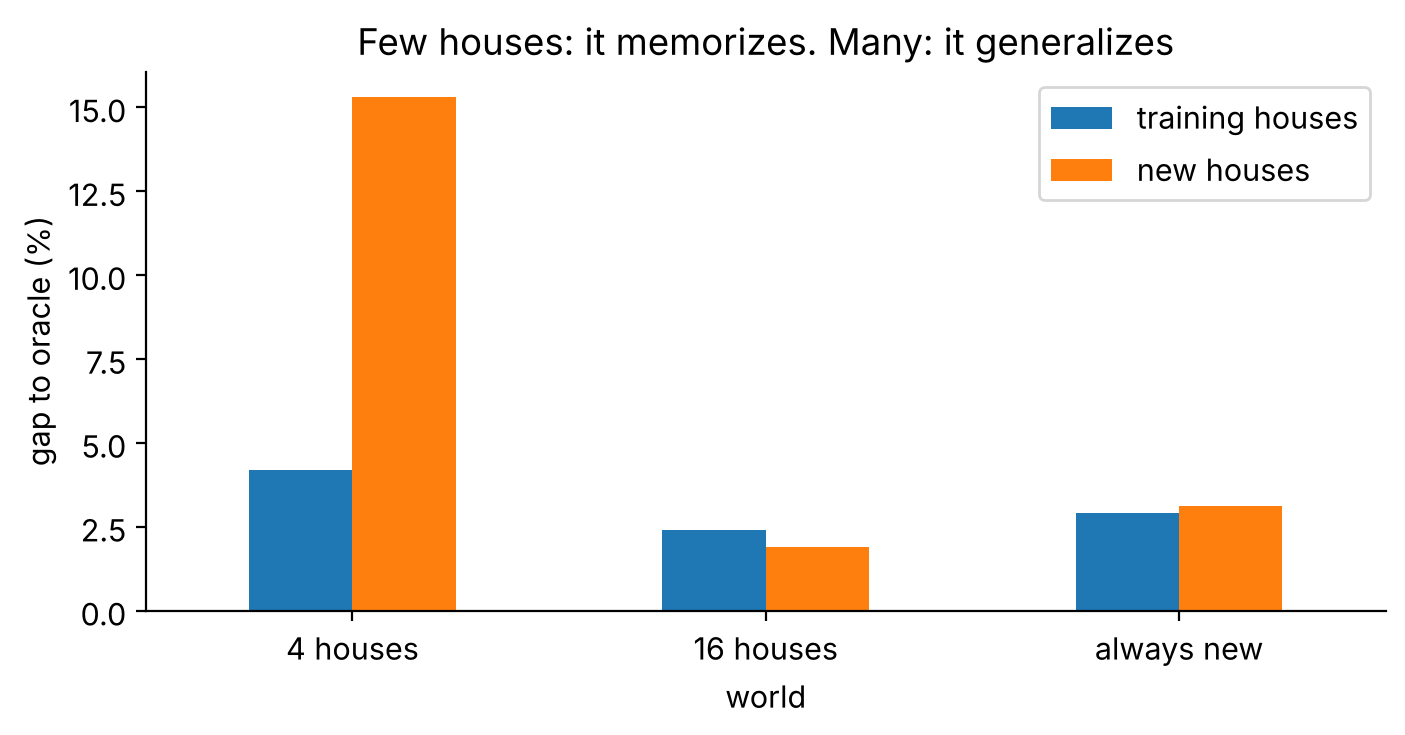

,training houses,new houses
world,,
4 houses,4.2,15.3
16 houses,2.4,1.9
always new,2.9,3.1


In [13]:
rows = []
for name, k in [("memorize_4", 4), ("memorize_16", 16), ("in_context", None)]:
    ag, _ = load_agent(name)
    if k:
        xi_k = sample_houses(k, 1.0, np.random.default_rng(11))      # the same k houses it was trained on
        idx = np.arange(256) % k
        xi_train = {key: v[idx] for key, v in xi_k.items()}
    else:
        xi_train = sample_houses(256, 1.0, np.random.default_rng(99))
    ref_train = cost_per_day(evaluate(oracle, weather, xi_train, starts_test, privileged=True)).mean()
    c_train = cost_per_day(evaluate(ag, weather, xi_train, starts_test)).mean()
    c_test = res["GRU + head"].mean() if not k else cost_per_day(evaluate(ag, weather, xi_test, starts_test)).mean()
    rows.append(dict(world=f"{k} houses" if k else "always new",
                     **{"training houses": 100 * (c_train / ref_train - 1),
                        "new houses": 100 * (c_test / res["oracle (sees ξ)"].mean() - 1)}))
gen = pd.DataFrame(rows).set_index("world").round(1)
gen.plot.bar(rot=0, figsize=(8, 3.5), ylabel="gap to oracle (%)", title="Few houses: it memorizes. Many: it generalizes")
plt.show(); gen

<details><summary><b>Instructor notes: memorize or recognize</b></summary>

Expected, as gaps to the oracle: **4 houses**: +4% on its training houses, +15% on new ones. It learned those 4 houses by heart, like an overfit model. **16 houses**: about +2% on both: with enough variety, it learned to recognize houses instead. **Always new**: about +3% on both. With a memory, generalizing means identifying a house never seen before from its behavior: that is learning in context.

For the "always new" row, "training houses" are simply fresh random houses, since that agent never saw the same house twice.

</details>

**Learning in context.** The weights are now frozen: only the memory changes as the agent watches the house. Below, each dot is a test house, placed by the first two principal components of the agent's 64-number memory and colored by its insulation.

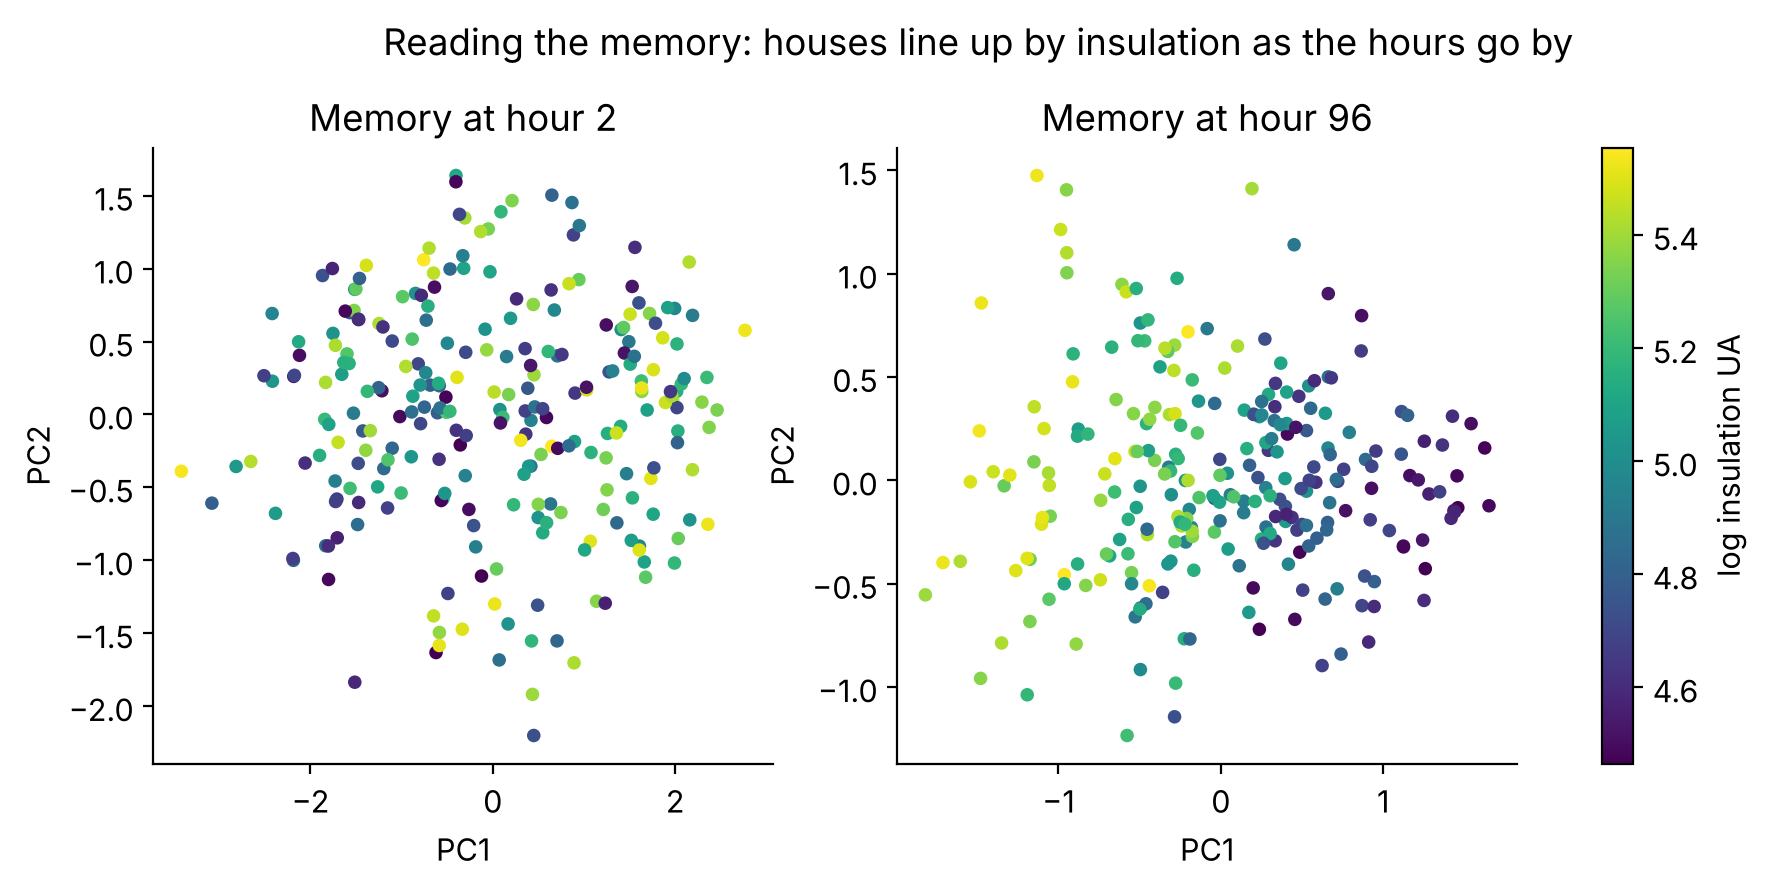

In [14]:
from sklearn.decomposition import PCA
d = evaluate(in_context, weather, xi_test, starts_test)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, t in zip(axs, (2, 96)):
    p = PCA(2).fit_transform(d["m"][:, t])
    s = ax.scatter(p[:, 0], p[:, 1], c=np.log(xi_test["UA"]), cmap="viridis", s=15)
    ax.set(title=f"Memory at hour {t}", xlabel="PC1", ylabel="PC2")
plt.colorbar(s, ax=axs, label="log insulation UA"); fig.suptitle("Reading the memory: houses line up by insulation as the hours go by", y=1.04); plt.show()

<details><summary><b>Instructor notes: learning in context</b></summary>

At hour 2 the colors are mixed: the agent has not watched the house long enough. At hour 96 they form a gradient along the first axis, leaky houses (yellow) on one side and well-insulated ones (purple) on the other: the memory now encodes how leaky the house is, learned only by watching it. This is learning in context: adaptation without any gradient step, the way an LLM picks up a task from the examples in its prompt.

</details>

> **Towards general control.** The agent identifies a house it has never seen within a few hours, without touching its weights, like an LLM picking up a task from the examples in its prompt. One case is left: the house that changes.

## 7 · Meta-RL: when the house changes mid-episode

So far a house stays the same for the whole week. Real houses change: a heat pump fails, a window is left open. An agent that identified the house once must keep re-identifying it.

Why that is hard: an estimate that averages **all** of the past (`expanding().mean()`) reacts more and more slowly. After a jump, it takes as long to correct halfway as its age at the time of the jump: that is its **half-life**. An estimate that forgets (`ewm`, an exponentially weighted mean) keeps a constant half-life.

In [15]:
# EXERCISE 5/5 · The half-life of an estimate after a jump
def half_life(t0, method, n=400):
    x = pd.Series(np.r_[np.zeros(t0), np.ones(n - t0)])        # the parameter jumps from 0 to 1 at hour t0
    # YOUR CODE HERE: cumulative or exponential estimate (half-life 12 h)
    est = x.expanding().mean() if method == "cumulative" else x.ewm(halflife=12).mean()
    return int(np.argmax(est.values[t0:] >= 0.5))               # hours after the jump until the estimate passes 0.5

print(pd.DataFrame({m: [half_life(t0, m) for t0 in (12, 24, 48, 96, 192)] for m in ("cumulative", "exponential")},
                   index=pd.Index([12, 24, 48, 96, 192], name="age at the jump (h)")))

                     cumulative  exponential
age at the jump (h)                         
12                           11            7
24                           23            9
48                           47           11
96                           95           11
192                         191           11


<details><summary><b>Instructor notes: exercise 5</b></summary>

Expected: cumulative 11, 23, 47, 95, 191 (about the age at the jump), exponential 7, 9, then 11 every time (constant). The message: an agent trained on houses that never change has no reason to forget, so it behaves like the cumulative mean and gets slower and slower. To keep adapting, it must be trained on a world that changes: that is the meta-RL step.

</details>

In the simulator, the drift strikes at a random hour: the heat pump loses half its power, or the insulation degrades by a factor of 1.8. We compare the agent trained without drift to the one trained with drift.

In [16]:
drift_agent, _ = load_agent("drift")
oracle_d, _ = load_agent("oracle_drift")
env_d = Houses(weather, 256, drift=True, seed=123); env_d.reset(xi=xi_test, starts=starts_test)   # same jumps as in evaluate()
t_jump = env_d.t_jump
after = lambda d: np.mean([d["cost"][i, t_jump[i]:t_jump[i] + 48].sum() for i in range(len(t_jump))]) / 2
rows, traces = {}, {}
for name, ag, priv in [("GRU + head, trained without drift", in_context, False), ("GRU + head, trained with drift", drift_agent, False),
                       ("oracle (sees ξ live)", oracle_d, True)]:
    d = evaluate(ag, weather, xi_test, starts_test, privileged=priv, drift=True)
    rows[name] = (cost_per_day(d).mean(), after(d)); traces[name] = d["Ta"]
ref = rows["oracle (sees ξ live)"]
drift_tab = pd.DataFrame({k: {"cost over the week ($/day)": v[0], "cost in the 48 h after the jump ($/day)": v[1],
                              "gap to oracle after the jump (%)": 100 * (v[1] / ref[1] - 1)} for k, v in rows.items()}).T.round(2)
drift_tab

,cost over the week ($/day),cost in the 48 h after the jump ($/day),gap to oracle after the jump (%)
"GRU + head, trained without drift",11.50,13.34,11.84
"GRU + head, trained with drift",11.63,12.54,5.09
oracle (sees ξ live),10.86,11.93,0.00


<details><summary><b>Instructor notes: drift</b></summary>

Expected: in the 48 h after the jump, the agent trained without drift is about **+12%** above the oracle, the one trained with drift about **+5%**. Over the whole week they are close (11.5 and 11.6 \$/day): the jump affects only part of the week, which is why the table zooms on the 48 hours after it. Costs are higher than in Section 3 because the houses got worse.

</details>

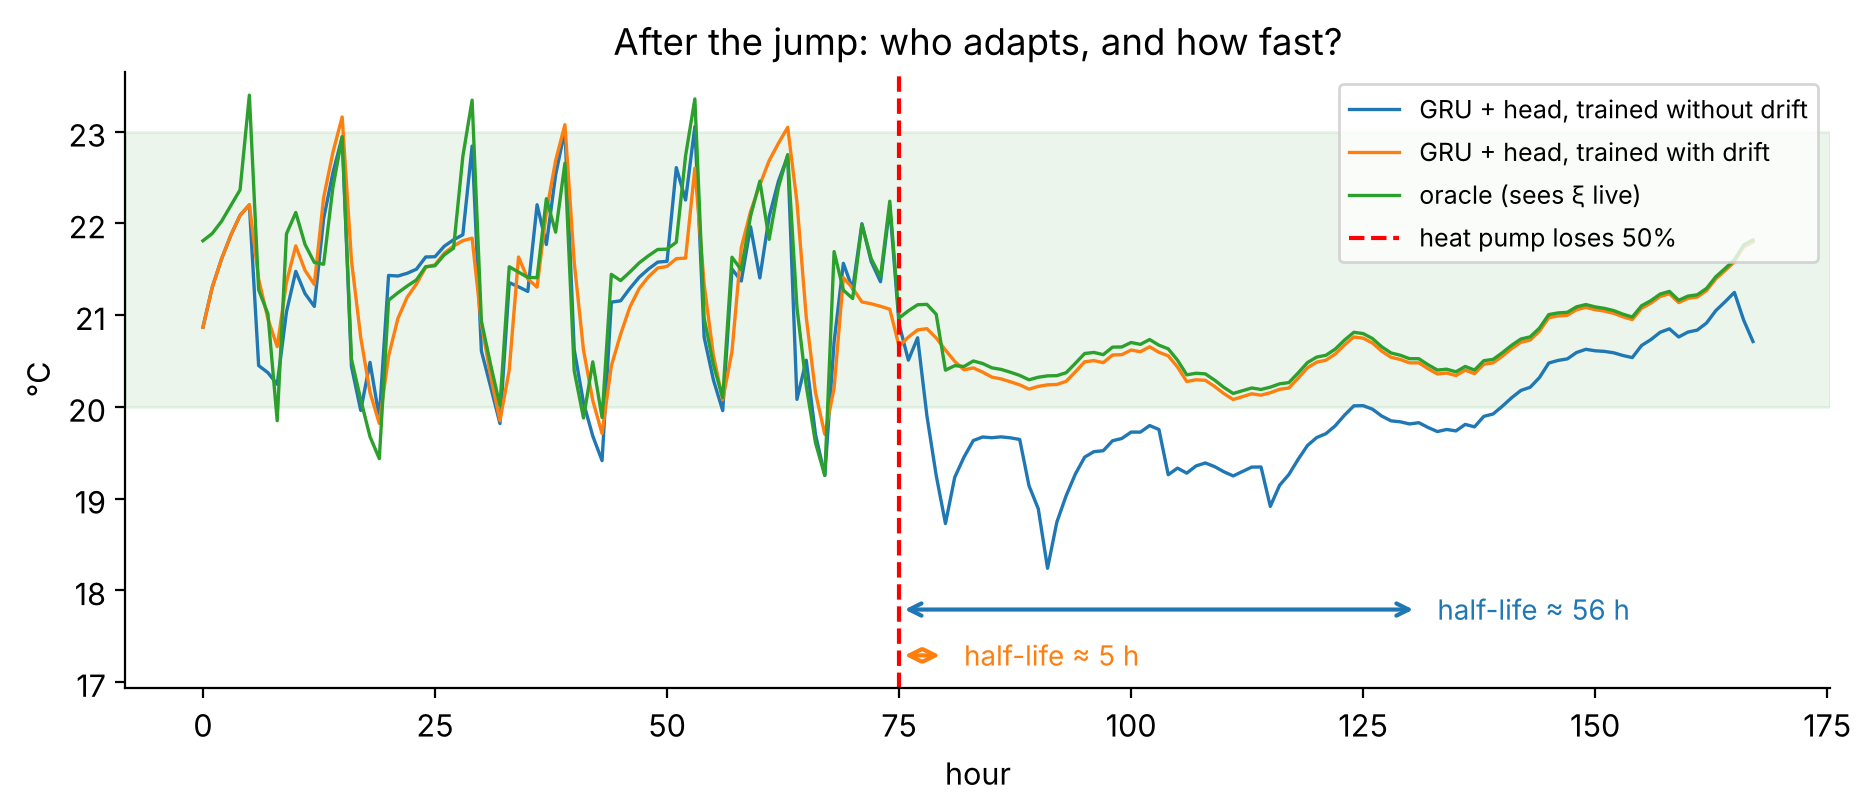

In [17]:
# one house whose heat pump loses half its power, picked where the gap between the two agents is clearest
names = list(traces)
disc_after = lambda Ta, i: np.maximum(COMFORT_BAND[0] - Ta[i, t_jump[i]:t_jump[i] + 48], 0).sum()
candidates = [j for j in np.where(env_d.jump_type == 0)[0] if disc_after(traces[names[2]], j) < 2]
i = max(candidates, key=lambda j: disc_after(traces[names[0]], j) - disc_after(traces[names[1]], j))

def gap_half_life(Ta, Ta_ref, t0, smooth=6):
    """Hours after the jump until the temperature gap to the oracle falls below half its maximum."""
    g = pd.Series(Ta_ref - Ta).rolling(smooth, min_periods=1).mean().values[t0:]
    top = int(g.argmax())
    below = np.where(g[top:] < g[top] / 2)[0]
    return top + int(below[0]) if len(below) else len(g), g[top]

fig, ax = plt.subplots(figsize=(11, 4))
for name, Ta in traces.items():
    ax.plot(Ta[i], label=name, lw=1.2)
t0 = t_jump[i]
ax.axvline(t0, color="r", ls="--", label="heat pump loses 50%"); ax.axhspan(*COMFORT_BAND, color="g", alpha=.08)
low = min(Ta[i].min() for Ta in traces.values())
ax.set_ylim(low - 1.3, None)
for k, (name, y) in enumerate([(names[0], low - 0.45), (names[1], low - 0.95)]):
    n12, top = gap_half_life(traces[name][i], traces[names[2]][i], t0)
    if top > 0.2:
        ax.annotate("", xy=(t0 + n12, y), xytext=(t0, y), arrowprops=dict(arrowstyle="<->", color=f"C{k}", lw=1.5))
        ax.text(t0 + n12 + 2, y, f"half-life ≈ {n12} h", va="center", color=f"C{k}", fontsize=10)
    else:
        ax.text(t0 + 2, y, "negligible gap to the oracle", va="center", color=f"C{k}", fontsize=10)
ax.set(xlabel="hour", ylabel="°C", title="After the jump: who adapts, and how fast?"); ax.legend(fontsize=9, loc="upper right"); plt.show()

<details><summary><b>Instructor notes: the example house</b></summary>

Expected: after the pump loses half its power, the agent trained without drift lets the house fall below 20 °C for about two days; the drift-trained agent stays with the oracle inside the comfort band. The arrows mark each agent's **half-life**: the time after the jump for its temperature gap to the oracle to fall back to half its maximum. Expected: about 56 h without drift training, about 5 h with it. This house was *picked* as the one where the difference is largest: it illustrates, the table above is the evidence.

</details>

The **half-life** can be read on the figure: the time after the jump for the temperature gap to the oracle to fall back to half its maximum.

**Question:** compare with Exercise 5. Which agent behaves like the cumulative mean, and which like the exponential one?

<details><summary><b>Answer</b></summary>

The agent trained without drift behaves like the cumulative mean: its memory has learned that a house never changes, so it is slow to revise what it believes (half-life of about two days here). The drift-trained agent behaves like the exponential mean: it has learned to forget, and it re-identifies the house within hours.

</details>

> **Towards general control.** Trained on houses that change, the agent keeps learning after deployment, with frozen weights. That is meta-RL: the top rung.

## 8 · Wrap-up: where each agent stopped

In [18]:
summary = pd.DataFrame({"cost ($/day)": {k: v.mean() for k, v in res.items()}})
summary["gap to oracle (%)"] = 100 * (summary["cost ($/day)"] / res["oracle (sees ξ)"].mean() - 1)
summary.sort_values("cost ($/day)", ascending=False).round(2)

,cost ($/day),gap to oracle (%)
classic (one house),12.50,126.31
thermostat,10.36,87.53
robust (no memory),6.09,10.36
"GRU, no head (saddle)",5.85,5.98
GRU + head,5.69,3.06
oracle (sees ξ),5.52,0.00


| Regime | Training world | Agent of the day | What it can do |
| --- | --- | --- | --- |
| Classic RL | one house | classic agent | beats the thermostat at home, fails elsewhere |
| Robust | random houses | memoryless MLP; GRU without head, near the saddle | one compromise at +10% above the oracle |
| Memorize or recognize | 4 or 16 houses | GRU + head | with 4 houses it memorizes; from 16, it recognizes |
| Learn in context | a new house every episode | GRU + head | identifies a house never seen, at +3% above the oracle |
| Meta-RL | the house changes during the episode | GRU + head, trained with drift | re-adapts after a failure |

**General control, in short.** An MPC needs the model of each house; our last agent needs only its history. At full scale, the NOMAD research project behind this lab stayed near the saddle: the memory knew a little, but the policy did not read it. Making this work on real buildings is still an open question.

<details><summary><b>Instructor notes: five take-home messages</b></summary>

1. RL learns from the return, not from labels. REINFORCE is a logistic regression weighted by the return.
2. Randomizing the training world buys robustness, at a price (here about +10% above the oracle).
3. A memory alone is not enough: at the saddle nothing pushes the agent to use it. A self-supervised prediction task gets it moving.
4. With enough variety in training, memorizing turns into recognizing: the agent identifies a new house within the episode. That is learning in context, with no weight update, like an LLM using the examples in its prompt.
5. To keep adapting, train on a world that changes. That is meta-RL.

</details>